# 04 – Labeling and Data Split

## 1. Goal
Label the roof crops from notebook 03 by hand (PV yes / no) and split them into training, validation and test data.

## 2. Inputs / Outputs
| | |
| --- | --- |
| **Inputs** | `data/processed/crops/<municipality>/unsorted/*.png` (from notebook 03), `data/interim/roofs_*.gpkg`, `data/interim/pv_register_*.gpkg` |
| **Outputs** | `data/labels/labels_<municipality>.csv` (our labels), `data/labels/train.csv`, `data/labels/val.csv`, `data/labels/test.csv` |

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import clear_output
from sklearn.model_selection import train_test_split

## 3. Analysis
### 3.1 Labeling tool
The function shows one image after the other. You type the label and press Enter:
- `1` = PV on this roof surface
- `0` = no PV
- `2` = unclear (e.g. too dark, solar thermal or not sure). These images are not used later.
- `q` = stop. Every answer is saved right away, so you can stop at any time and continue later.

The labels are saved as CSV in `data/labels/` (this folder is versioned in git).

In [2]:
def label_images(municipality):
    folder = f"../data/processed/crops/{municipality}/unsorted"
    labels_file = f"../data/labels/labels_{municipality}.csv"

    if os.path.exists(labels_file):
        labels = pd.read_csv(labels_file)
    else:
        labels = pd.DataFrame(columns=["DF_UID", "label"])

    files = sorted(os.listdir(folder))
    for file in files:
        df_uid = int(file.replace(".png", ""))
        if df_uid in labels["DF_UID"].values:
            continue    # already labeled

        image = plt.imread(f"{folder}/{file}")
        plt.figure(figsize=(5, 5))
        plt.imshow(image)
        plt.title(f"{len(labels) + 1} / {len(files)}")
        plt.axis("off")
        plt.show()

        answer = input("1 = PV, 0 = no PV, 2 = unclear, q = quit: ")
        while answer not in ["0", "1", "2", "q"]:
            answer = input("Please type 0, 1, 2 or q: ")
        if answer == "q":
            break

        labels.loc[len(labels)] = [df_uid, int(answer)]
        labels.to_csv(labels_file, index=False)
        clear_output()

    print(municipality, ":", len(labels), "of", len(files), "images labeled")

Run one cell after the other. We can split the work: Timono labels Rapperswil-Jona and Uznach, Pascal Lutry and Pully.

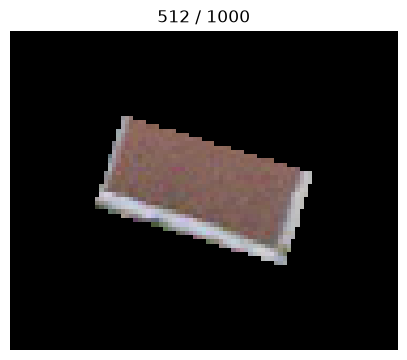

rapperswil-jona : 511 of 1000 images labeled


In [4]:
label_images("rapperswil-jona")

In [6]:
label_images("lutry")

lutry : 1000 of 1000 images labeled


In [ ]:
label_images("uznach")

In [7]:
label_images("pully")

pully : 400 of 400 images labeled


**Observation:** Pictures low quality. About 10% were really hard to identify and mostly guessing if shadow or just zoomed in on pv

### 3.2 Overview of the labels

In [4]:
labels = []
for municipality in ["rapperswil-jona", "lutry", "uznach", "pully"]:
    df = pd.read_csv(f"../data/labels/labels_{municipality}.csv")
    df["municipality"] = municipality
    labels.append(df)
labels = pd.concat(labels)

pd.crosstab(labels["municipality"], labels["label"], margins=True)

FileNotFoundError: [Errno 2] No such file or directory: '../data/labels/labels_rapperswil-jona.csv'

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for row, label in enumerate([1, 0]):
    examples = labels[labels["label"] == label].sample(6, random_state=0)
    for ax, (i, example) in zip(axes[row], examples.iterrows()):
        ax.imshow(plt.imread(f"../data/processed/crops/{example['municipality']}/unsorted/{example['DF_UID']}.png"))
        ax.set_title("PV" if label == 1 else "no PV")
        ax.axis("off")
plt.show()

**Observation:** _comment on output_

### 3.3 How good is the BFE register on roof level?
Half of the images come from buildings with a PV plant in the register. How many of these roof surfaces really have PV on the image?

In [ ]:
for municipality in ["rapperswil-jona", "lutry", "uznach", "pully"]:
    roofs = gpd.read_file(f"../data/interim/roofs_{municipality}.gpkg")
    pv = gpd.read_file(f"../data/interim/pv_register_{municipality}.gpkg")
    roofs["in_register"] = roofs["GWR_EGID"].isin(pv["EGID"])

    df = labels[labels["municipality"] == municipality]
    df = df.merge(roofs[["DF_UID", "in_register"]], on="DF_UID")

    print(municipality)
    print(pd.crosstab(df["in_register"], df["label"]))
    print()

**Observation:** _comment on output_

### 3.4 Split into training, validation and test data
- **Training + validation**: Rapperswil-Jona and Lutry, split 80 / 20 (stratified, so both parts have the same share of PV).
- **Test**: Uznach and Pully. The model never sees these images during training.

Images with label 2 (unclear) are removed.

In [ ]:
labels = labels[labels["label"] != 2]
labels["path"] = "../data/processed/crops/" + labels["municipality"] + "/unsorted/" + labels["DF_UID"].astype(str) + ".png"

train_val = labels[labels["municipality"].isin(["rapperswil-jona", "lutry"])]
test = labels[labels["municipality"].isin(["uznach", "pully"])]

train, val = train_test_split(train_val, test_size=0.2, stratify=train_val["label"], random_state=42)

print("train:", len(train), "images,", round(train["label"].mean() * 100, 1), "% PV")
print("val:  ", len(val), "images,", round(val["label"].mean() * 100, 1), "% PV")
print("test: ", len(test), "images,", round(test["label"].mean() * 100, 1), "% PV")

In [ ]:
train.to_csv("../data/labels/train.csv", index=False)
val.to_csv("../data/labels/val.csv", index=False)
test.to_csv("../data/labels/test.csv", index=False)

**Observation:** _comment on output_

## 4. Conclusion & Open Points
- _summary_